# 02 – Modélisation et prévisions

Prévision des ventes hebdomadaires totales du bonnet de ski (55 magasins) pour les 40 semaines du test
(`week_id` 202335 → 202422). Deux modèles sont testés à chaque étape :

| Étape | Modèle 1 | Modèle 2 |
|---|---|---|
| 2. Baselines | Seasonal naive | Seasonal naive ajusté par `n_stores` |
| 3. Méthodes classiques | ARIMA | SARIMAX |
| 4. Machine learning | Random Forest | XGBoost |
| 5. Deep learning simple | MLP | LSTM |
| 6. Deep learning avancé | TFT | N-HiTS |

Tous les modèles sont évalués sur **le même fold de validation** (voir EDA, section 6) avec la **MSE**,
puis réentraînés sur tout l'historique pour produire une soumission.

## 1. Préparation

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 4)

DATA_DIR = Path('../centrale-lille-decathlon-forecast-project-10-2026')
SUB_DIR = Path('../submissions')
SUB_DIR.mkdir(exist_ok=True)

train = pd.read_csv(DATA_DIR / 'train.csv', parse_dates=['date'])
test = pd.read_csv(DATA_DIR / 'test.csv', parse_dates=['date'])
sample_sub = pd.read_csv(DATA_DIR / 'submission.csv')

### 1.1 Série hebdomadaire

Une ligne par semaine avec le total des ventes (`sales`, inconnu sur le test) et le nombre de magasins ayant vendu
(`n_stores`, connu aussi sur le test). Les semaines absentes du train correspondent à 0 vente.

In [2]:
def weekly(df):
    agg = df.groupby('date').agg(n_stores=('bu', 'size'), week_id=('week_id', 'first'))
    if 'sales_quantity' in df:
        agg['sales'] = df.groupby('date').sales_quantity.sum()
    return agg

w_train, w_test = weekly(train), weekly(test)
full_idx = pd.date_range(w_train.index.min(), w_test.index.max(), freq='W-SUN')
w = pd.concat([w_train, w_test]).reindex(full_idx)
w.index.name = 'date'

is_train = w.index <= train.date.max()
w.loc[is_train, ['sales', 'n_stores']] = w.loc[is_train, ['sales', 'n_stores']].fillna(0)
w['n_stores'] = w['n_stores'].fillna(0).astype(int)
# week_id Decathlon = semaine ISO du lendemain (la semaine commence le dimanche)
iso = (w.index + pd.Timedelta(days=1)).isocalendar()
w['week_id'] = (iso.year * 100 + iso.week).values

hist = w[is_train].copy()          # tout l'historique connu
future = w[~is_train].copy()       # 40 semaines à prévoir
assert (future.week_id.values == sample_sub.ID.values).all()
print(f'Historique : {len(hist)} semaines | à prévoir : {len(future)} semaines')
w.tail()

Historique : 102 semaines | à prévoir : 40 semaines


,n_stores,week_id,sales
date,,,
2024-04-28,2,202418,NaN
2024-05-05,3,202419,NaN
2024-05-12,2,202420,NaN
2024-05-19,1,202421,NaN
2024-05-26,2,202422,NaN


### 1.2 Fold de validation

On reproduit la situation du test : entraînement jusqu'au 21/08/2022, prévision des 40 semaines suivantes
(28/08/2022 → 28/05/2023).

In [3]:
VAL_START = pd.Timestamp('2022-08-28')
H = 40
val_train = hist[hist.index < VAL_START]
val_future = hist[hist.index >= VAL_START].iloc[:H]
y_val = val_future.sales
print('Train :', val_train.index[0].date(), '→', val_train.index[-1].date(), f'({len(val_train)} sem.)')
print('Val   :', val_future.index[0].date(), '→', val_future.index[-1].date(), f'({len(val_future)} sem.)')

Train : 2021-09-12 → 2022-08-21 (50 sem.)
Val   : 2022-08-28 → 2023-05-28 (40 sem.)


### 1.3 Fonctions communes

Chaque modèle est une fonction `forecast(past, fut)` :
- `past` : historique (colonnes `sales`, `n_stores`, `week_id`)
- `fut` : semaines à prévoir (`n_stores`, `week_id` ; pas de `sales`)
- renvoie une `pd.Series` de prévisions indexée comme `fut`

La même fonction sert pour la validation et pour la soumission finale.

In [4]:
results = {}       # métriques de validation par modèle
val_preds = {}     # prévisions de validation par modèle

def metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    err = y_true - y_pred
    return {'MSE': np.mean(err ** 2), 'RMSE': np.sqrt(np.mean(err ** 2)),
            'MAE': np.mean(np.abs(err)), 'WAPE': np.abs(err).sum() / np.abs(y_true).sum()}

def evaluate(name, forecast):
    """Entraîne sur le fold, prévoit les 40 semaines de validation, enregistre et affiche les métriques."""
    pred = forecast(val_train, val_future.drop(columns='sales')).clip(lower=0)
    val_preds[name] = pred
    results[name] = metrics(y_val, pred)
    print(name, '|', ' | '.join(f'{k} = {v:,.3f}' if k == 'WAPE' else f'{k} = {v:,.0f}' for k, v in results[name].items()))
    return pred

def plot_val(names, title='Validation: forecast vs actual'):
    fig, ax = plt.subplots()
    ax.plot(y_val.index, y_val, color='k', lw=2, label='Actual')
    for n in names:
        ax.plot(val_preds[n].index, val_preds[n], marker='.', label=n)
    ax.set_title(title); ax.set_ylabel('units sold'); ax.legend(); plt.show()

def make_submission(name, forecast):
    """Réentraîne sur tout l'historique, prévoit le test et écrit le fichier de soumission."""
    pred = forecast(hist, future.drop(columns='sales')).clip(lower=0)
    sub = pd.DataFrame({'ID': future.week_id.values, 'TARGET': pred.values})
    path = SUB_DIR / f'{name}.csv'
    sub.to_csv(path, index=False)
    print(f'Soumission écrite : {path} ({len(sub)} lignes, total prévu = {sub.TARGET.sum():,.0f})')
    return pred

def results_table():
    return pd.DataFrame(results).T.sort_values('MSE').style.format(
        {'MSE': '{:,.0f}', 'RMSE': '{:,.0f}', 'MAE': '{:,.0f}', 'WAPE': '{:.1%}'})

## 2. Baselines

Modèles très simples, sans apprentissage, qui servent de référence : un modèle plus complexe n'est utile
que s'il fait mieux qu'eux.

### 2.1 Seasonal naive

Prévision = ventes de **la même semaine l'année précédente** (52 semaines plus tôt) :

$$\hat{y}_t = y_{t-52}$$

Si la semaine t−52 est antérieure au début des données, la prévision vaut 0 (période creuse).

In [5]:
def seasonal_naive(past, fut):
    lag = fut.index - pd.Timedelta(weeks=52)
    return pd.Series(past.sales.reindex(lag).fillna(0).values, index=fut.index)

evaluate('Seasonal naive', seasonal_naive);

Seasonal naive | MSE = 409,124 | RMSE = 640 | MAE = 392 | WAPE = 0.428


### 2.2 Seasonal naive ajusté par `n_stores`

On sait combien de magasins vendront chaque semaine du test. On garde les **ventes moyennes par magasin actif**
de l'année précédente et on les multiplie par le nombre de magasins actifs de la semaine à prévoir :

$$\hat{y}_t = n\_stores_t \times \frac{y_{t-52}}{n\_stores_{t-52}}$$

Ainsi, si la saison démarre plus tôt ou plus tard que l'année précédente, la prévision suit.

In [6]:
def seasonal_naive_stores(past, fut):
    lag = fut.index - pd.Timedelta(weeks=52)
    per_store = (past.sales / past.n_stores.replace(0, np.nan)).reindex(lag).fillna(0)
    return pd.Series(fut.n_stores.values * per_store.values, index=fut.index)

evaluate('Seasonal naive × n_stores', seasonal_naive_stores);

Seasonal naive × n_stores | MSE = 416,524 | RMSE = 645 | MAE = 395 | WAPE = 0.432


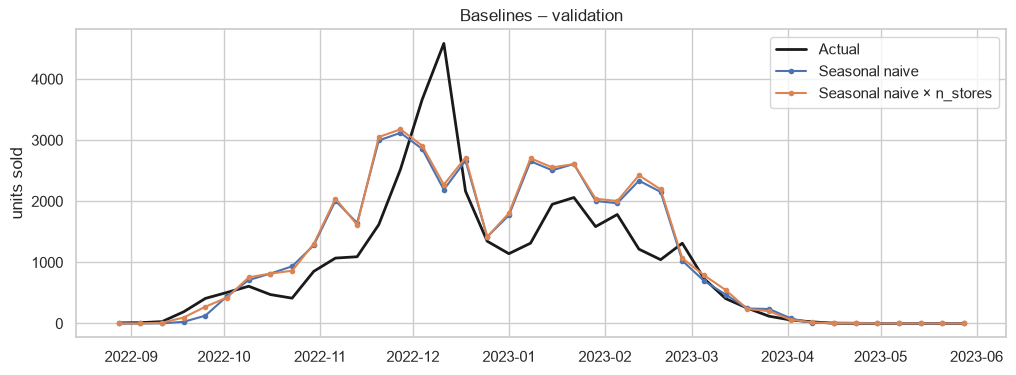

,MSE,RMSE,MAE,WAPE
Seasonal naive,"409,124",640,392,42.8%
Seasonal naive × n_stores,"416,524",645,395,43.2%


In [7]:
plot_val(['Seasonal naive', 'Seasonal naive × n_stores'], 'Baselines – validation')
results_table()

### 2.3 Analyse des baselines

- Les deux baselines obtiennent des scores quasi identiques (MSE ≈ 409 000 contre ≈ 417 000, WAPE ≈ 43 %).
- **L'ajustement par `n_stores` n'apporte rien** : en pleine saison, `n_stores` vaut ≈ 55 les deux années, donc le ratio est ≈ 1.
  Il n'agit qu'en début et fin de saison, où les volumes sont faibles et pèsent peu dans la MSE.
- **L'erreur vient surtout du pic** : en 2021-22 le pic a eu lieu fin novembre, en 2022-23 à la mi-décembre, plus haut (≈ 4 600).
  Copier l'année précédente décale le pic et sous-estime son niveau, puis surestime janvier–février (saison 2022-23 plus faible de 17 %).
- Pour la soumission, le seasonal naive copie la saison 2022-23, y compris son pic exceptionnel de décembre.
- Pistes pour les modèles suivants : utiliser les **deux saisons** disponibles (moyenne), aligner sur le **calendrier**
  (Black Friday, semaines avant Noël) plutôt que sur un décalage fixe de 52 semaines.

In [8]:
for name, fn in [('baseline_seasonal_naive', seasonal_naive),
                 ('baseline_seasonal_naive_stores', seasonal_naive_stores)]:
    make_submission(name, fn)

Soumission écrite : ..\submissions\baseline_seasonal_naive.csv (40 lignes, total prévu = 36,582)
Soumission écrite : ..\submissions\baseline_seasonal_naive_stores.csv (40 lignes, total prévu = 36,501)


## 3. Méthodes classiques

Modèles statistiques ajustés sur le **log des ventes** (`log1p`) avec **d = 1**, comme suggéré par l'EDA
(tests ADF/KPSS). Les prévisions sont ensuite ramenées à l'échelle d'origine avec `expm1`.

In [9]:
import itertools
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
warnings.filterwarnings('ignore', module='statsmodels')

### 3.1 ARIMA

Le modèle n'utilise **que l'historique des ventes**. Les ordres p et q (de 0 à 2) sont choisis par **AIC**
(critère d'information : bon ajustement, pénalisé par le nombre de paramètres). L'EDA suggérait ARIMA(1,1,0).

In [10]:
def arima_aic_grid(y, d=1, max_p=2, max_q=2):
    rows = []
    for p, q in itertools.product(range(max_p + 1), range(max_q + 1)):
        try:
            rows.append({'order': (p, d, q), 'AIC': ARIMA(y, order=(p, d, q)).fit().aic})
        except Exception:
            pass
    return pd.DataFrame(rows).sort_values('AIC').reset_index(drop=True)

def arima_forecast(past, fut):
    y = np.log1p(past.sales.values)
    order = arima_aic_grid(y).order[0]
    model = ARIMA(y, order=order).fit()
    return pd.Series(np.expm1(model.forecast(len(fut))), index=fut.index)

display(arima_aic_grid(np.log1p(val_train.sales.values)).head())
evaluate('ARIMA', arima_forecast);

,order,AIC
0,"(1, 1, 1)",107.668065
1,"(1, 1, 2)",107.717223
2,"(2, 1, 1)",108.215800
3,"(2, 1, 0)",109.098770
4,"(2, 1, 2)",110.378400


ARIMA | MSE = 1,876,560 | RMSE = 1,370 | MAE = 907 | WAPE = 0.992


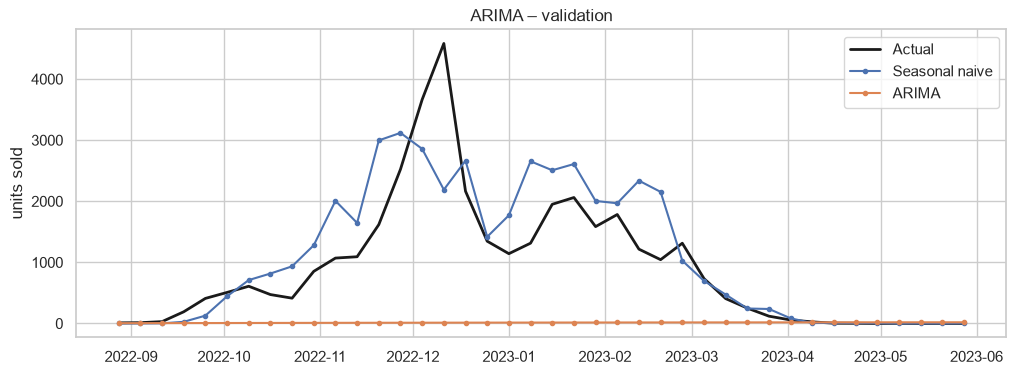

In [11]:
plot_val(['Seasonal naive', 'ARIMA'], 'ARIMA – validation')

**Lecture :** sans information saisonnière, l'ARIMA prolonge simplement la dynamique des dernières semaines connues
(fin de l'été, ventes quasi nulles). Sur un horizon de 40 semaines, sa prévision ne voit pas arriver la saison
d'hiver : la MSE est bien pire que celle des baselines. Un ARIMA « pur » n'est donc pas adapté à ce problème.

### 3.2 SARIMAX

Un SARIMA classique ajoute une composante saisonnière de période s = 52, mais il faut au moins deux cycles
complets pour l'estimer ; or le fold de validation ne contient que 50 semaines. On apporte donc la saisonnalité
et le calendrier par des **variables exogènes (X)** :

- `log_stores` = log(1 + `n_stores`) : nombre de magasins avec ventes, **connu sur la période à prévoir** ;
- **termes de Fourier annuels** (sinus et cosinus de période 52,18 semaines) : une courbe saisonnière lisse ;
- `pre_xmas` = 1 pendant les 5 semaines précédant Noël (Black Friday → Noël).

**Pourquoi d = 0 (et non d = 1) ?** Avec d = 1, le niveau de toute la prévision est ancré sur la **dernière semaine
observée**, en fin d'été, où les ventes sont quasi nulles (1 à 4 unités) : quelques unités de différence suffisent
à multiplier ou diviser la saison prévue (voir le test de sensibilité ci-dessous). Le log des ventes étant
stationnaire d'après l'ADF (p = 0,037), on utilise un modèle **AR(1) avec constante** (d = 0) : le niveau est alors
porté par les variables exogènes.

Les variables exogènes sont choisies par **AIC** sur la période d'entraînement (et non sur la validation, pour ne pas
sur-ajuster le fold). Les écarts d'AIC inférieurs à 2 n'étant pas significatifs, on retient le modèle le plus simple
parmi ceux à moins de 2 points du meilleur : **K = 1 et `pre_xmas`**.

In [12]:
def fourier_terms(idx, K, period=52.18):
    t = (idx - pd.Timestamp('2021-01-03')).days / 7
    return pd.DataFrame({f'{f}{k}': fn(2 * np.pi * k * t / period)
                         for k in range(1, K + 1) for f, fn in [('sin', np.sin), ('cos', np.cos)]}, index=idx)

def sarimax_exog(df, K=1, xmas=True):
    X = pd.DataFrame({'log_stores': np.log1p(df.n_stores)}, index=df.index)
    if K:
        X = X.join(fourier_terms(df.index, K))
    if xmas:
        days_to_xmas = np.array([(pd.Timestamp(year=d.year, month=12, day=25) - d).days for d in df.index])
        X['pre_xmas'] = ((days_to_xmas >= 0) & (days_to_xmas <= 35)).astype(int)
    return X

SARIMAX_ORDER, SARIMAX_TREND = (1, 0, 0), 'c'   # AR(1) + constante, d = 0

# Choix des variables exogènes par AIC (période d'entraînement du fold uniquement)
y_fold = np.log1p(val_train.sales.values)
aic_rows = [{'K Fourier': K, 'pre_xmas': xm,
             'AIC': SARIMAX(y_fold, exog=sarimax_exog(val_train, K, xm).values, order=SARIMAX_ORDER, trend=SARIMAX_TREND).fit(disp=False).aic}
            for K in [0, 1, 2] for xm in [False, True]]
display(pd.DataFrame(aic_rows).sort_values('AIC').round(1))

,K Fourier,pre_xmas,AIC
4,2,False,28.0
5,2,True,28.0
3,1,True,29.2
2,1,False,30.9
1,0,True,45.4
0,0,False,49.5


In [13]:
def sarimax_forecast(past, fut, K=1, xmas=True):
    model = SARIMAX(np.log1p(past.sales.values), exog=sarimax_exog(past, K, xmas).values,
                    order=SARIMAX_ORDER, trend=SARIMAX_TREND).fit(disp=False)
    pred = model.forecast(len(fut), exog=sarimax_exog(fut, K, xmas).values)
    return pd.Series(np.expm1(pred), index=fut.index)

evaluate('SARIMAX', sarimax_forecast);

# Diagnostic des résidus : test de Ljung-Box (H0 : résidus non autocorrélés = bruit blanc)
fit = SARIMAX(y_fold, exog=sarimax_exog(val_train).values, order=SARIMAX_ORDER, trend=SARIMAX_TREND).fit(disp=False)
display(acorr_ljungbox(fit.resid[1:], lags=[4, 8, 12]).round(3))
display(fit.summary().tables[1])

SARIMAX | MSE = 307,184 | RMSE = 554 | MAE = 317 | WAPE = 0.347


,lb_stat,lb_pvalue
4,6.098,0.192
8,13.012,0.111
12,21.707,0.041


,coef,std err,z,P>|z|,[0.025,0.975]
intercept,0.5868,0.153,3.828,0.000,0.286,0.887
x1,1.2659,0.101,12.491,0.000,1.067,1.464
x2,-0.2521,0.097,-2.605,0.009,-0.442,-0.062
x3,1.4915,0.241,6.190,0.000,1.019,1.964
x4,0.4111,0.291,1.413,0.158,-0.159,0.981
ar.L1,0.4872,0.136,3.577,0.000,0.220,0.754
sigma2,0.0790,0.018,4.485,0.000,0.044,0.113


In [14]:
# Test de sensibilité : total prévu sur le test selon les ventes de la DERNIÈRE semaine connue (août 2023)
rows = []
for last in [0, 1, 4, 10]:
    h = hist.copy()
    h.iloc[-1, h.columns.get_loc('sales')] = last
    row = {'ventes dernière semaine': last}
    for label, order, trend in [('total prévu d=1', (1, 1, 0), 'n'), ('total prévu d=0', (1, 0, 0), 'c')]:
        m = SARIMAX(np.log1p(h.sales.values), exog=sarimax_exog(h).values, order=order, trend=trend).fit(disp=False)
        row[label] = np.expm1(m.forecast(len(future), exog=sarimax_exog(future).values)).clip(0).sum()
    rows.append(row)
pd.DataFrame(rows).set_index('ventes dernière semaine').round(0)

,total prévu d=1,total prévu d=0
ventes dernière semaine,,
0,11859.0,37165.0
1,23707.0,37612.0
4,56980.0,38065.0
10,117088.0,38352.0


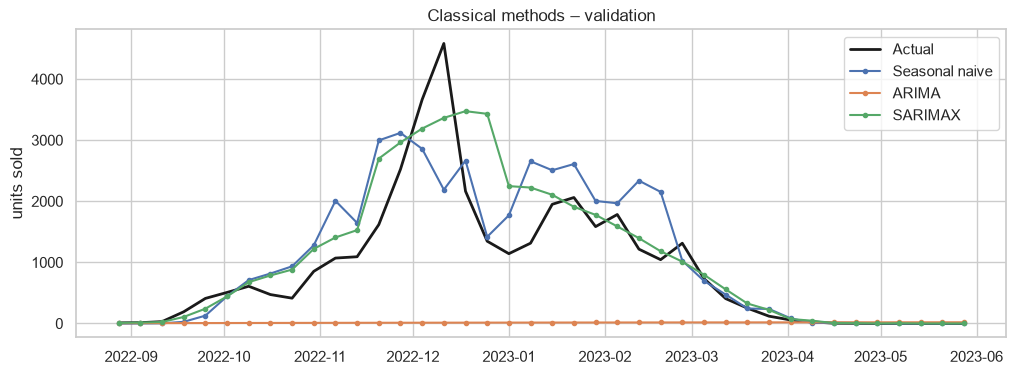

,MSE,RMSE,MAE,WAPE
SARIMAX,"307,184",554,317,34.7%
Seasonal naive,"409,124",640,392,42.8%
Seasonal naive × n_stores,"416,524",645,395,43.2%
ARIMA,"1,876,560","1,370",907,99.2%


In [15]:
plot_val(['Seasonal naive', 'ARIMA', 'SARIMAX'], 'Classical methods – validation')
results_table()

### 3.3 Analyse des méthodes classiques

| Modèle | MSE validation | WAPE |
|---|---|---|
| Seasonal naive (référence) | ≈ 409 000 | 42,8 % |
| ARIMA | ≈ 1 877 000 | 99,2 % |
| **SARIMAX** | **≈ 307 000** | **34,7 %** |

- **ARIMA :** inutilisable sur 40 semaines. Sans information saisonnière, il prolonge les ventes quasi nulles de fin d'été
  et ne voit pas arriver l'hiver (prévision totale ≈ 175 unités sur le test).
- **SARIMAX :** meilleur modèle à ce stade, **−25 % de MSE** par rapport au seasonal naive. Il reproduit bien la montée
  d'octobre–novembre et la descente de janvier à mars.
- **Coefficients** (`x1` = `log_stores`, `x2`/`x3` = sinus/cosinus de Fourier, `x4` = `pre_xmas`) : `log_stores` et la
  saisonnalité de Fourier sont très significatifs ; `pre_xmas` est positif mais non significatif (p ≈ 0,16).
- **Limites :**
  - le pic reste **lissé** : la courbe de Fourier est trop douce pour capter la semaine record (≈ 4 600) et le modèle
    surestime la semaine de Noël ;
  - le test de Ljung-Box détecte une légère autocorrélation résiduelle au lag 12 (p ≈ 0,04) ;
  - le choix de **d** est crucial : avec d = 1, le total prévu varie de ≈ 12 000 à ≈ 117 000 selon les ventes de la
    dernière semaine d'août (0 à 10 unités) ; avec d = 0 il reste stable (≈ 37 000 à 38 000).

In [16]:
for name, fn in [('classique_arima', arima_forecast), ('classique_sarimax', sarimax_forecast)]:
    make_submission(name, fn)

Soumission écrite : ..\submissions\classique_arima.csv (40 lignes, total prévu = 175)
Soumission écrite : ..\submissions\classique_sarimax.csv (40 lignes, total prévu = 37,612)


## 4. Machine learning

Les modèles à base d'arbres ne « lisent » pas la série dans l'ordre : ils apprennent une relation entre des
**variables explicatives (features)** et les ventes de chaque semaine. On n'utilise donc que des features
**connues à l'avance** pour les semaines à prévoir, ce qui permet de prévoir les 40 semaines d'un coup
(prévision directe, sans lags récursifs).

| Feature | Description |
|---|---|
| `season_week` | semaines depuis le 1er septembre (position dans la saison) |
| `weeks_to_xmas` | semaines restantes avant Noël |
| `weeks_from_bf` | semaines écoulées depuis le Black Friday (négatif avant) |
| `toussaint`, `noel`, `hiver` | 1 si la semaine chevauche les vacances scolaires de la zone C |
| `log_stores` | log(1 + nombre de magasins avec ventes), connu sur le test |

Comme pour les méthodes classiques, la cible est `log1p(sales)`. Le fold d'entraînement ne contient que
**50 semaines** : les hyperparamètres sont fixés à des valeurs raisonnables plutôt qu'optimisés, pour éviter
de sur-ajuster ce petit échantillon.

*Remarque :* la feature « ventes de la même semaine l'année précédente » n'est pas utilisée, car elle n'existe pas
pour la première saison, qui constitue tout l'entraînement du fold.

In [17]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

HOLIDAYS = {
    'toussaint': [('2021-10-23', '2021-11-08'), ('2022-10-22', '2022-11-07'), ('2023-10-21', '2023-11-06')],
    'noel':      [('2021-12-18', '2022-01-03'), ('2022-12-17', '2023-01-03'), ('2023-12-23', '2024-01-08')],
    'hiver':     [('2022-02-19', '2022-03-07'), ('2023-02-18', '2023-03-06'), ('2024-02-10', '2024-02-26')],
}
BLACK_FRIDAYS = pd.to_datetime(['2021-11-26', '2022-11-25', '2023-11-24'])
ML_FEATURES = ['season_week', 'weeks_to_xmas', 'weeks_from_bf', 'toussaint', 'noel', 'hiver', 'log_stores']

def ml_features(df):
    d = df.index
    season_year = np.where(d.month >= 8, d.year, d.year - 1)
    X = pd.DataFrame(index=d)
    X['season_week'] = (d - pd.to_datetime([f'{y}-09-01' for y in season_year])).days // 7
    X['weeks_to_xmas'] = (pd.to_datetime([f'{y}-12-25' for y in season_year]) - d).days / 7
    bf = pd.to_datetime([BLACK_FRIDAYS[BLACK_FRIDAYS.year == y][0] for y in season_year])
    X['weeks_from_bf'] = (d - bf).days / 7
    for name, spans in HOLIDAYS.items():
        # la semaine va du dimanche `date` au samedi suivant
        X[name] = np.any([(d + pd.Timedelta(days=6) >= a) & (d <= b) for a, b in spans], axis=0).astype(int)
    X['log_stores'] = np.log1p(df.n_stores.values)
    return X[ML_FEATURES]

def ml_forecast(make_model):
    """Construit une fonction forecast(past, fut) à partir d'un modèle scikit-learn."""
    def forecast(past, fut):
        model = make_model()
        model.fit(ml_features(past), np.log1p(past.sales))
        forecast.model = model
        return pd.Series(np.expm1(model.predict(ml_features(fut))), index=fut.index)
    return forecast

ml_features(val_future).head()

,season_week,weeks_to_xmas,weeks_from_bf,toussaint,noel,hiver,log_stores
date,,,,,,,
2022-08-28,-1,17.0,-12.714286,0,0,0,1.609438
2022-09-04,0,16.0,-11.714286,0,0,0,1.791759
2022-09-11,1,15.0,-10.714286,0,0,0,1.945910
2022-09-18,2,14.0,-9.714286,0,0,0,2.944439
2022-09-25,3,13.0,-8.714286,0,0,0,3.433987


### 4.1 Random Forest

Moyenne de 500 arbres de décision, chacun entraîné sur un échantillon bootstrap des semaines.
`min_samples_leaf = 2` empêche les arbres d'isoler une seule semaine.

In [18]:
rf_forecast = ml_forecast(lambda: RandomForestRegressor(n_estimators=500, min_samples_leaf=2,
                                                        random_state=42, n_jobs=-1))
evaluate('Random Forest', rf_forecast);

Random Forest | MSE = 368,001 | RMSE = 607 | MAE = 391 | WAPE = 0.427


### 4.2 XGBoost

Gradient boosting : les arbres sont construits les uns après les autres, chacun corrigeant les erreurs des
précédents. Arbres peu profonds (`max_depth = 3`) et petit taux d'apprentissage pour limiter le sur-apprentissage.

In [19]:
xgb_forecast = ml_forecast(lambda: XGBRegressor(n_estimators=400, learning_rate=0.03, max_depth=3,
                                                subsample=0.8, colsample_bytree=0.8, random_state=42))
evaluate('XGBoost', xgb_forecast);

XGBoost | MSE = 371,109 | RMSE = 609 | MAE = 381 | WAPE = 0.416


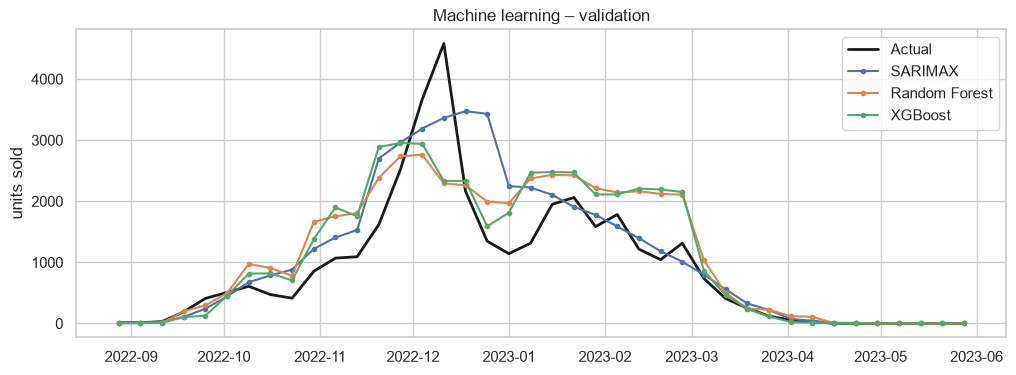

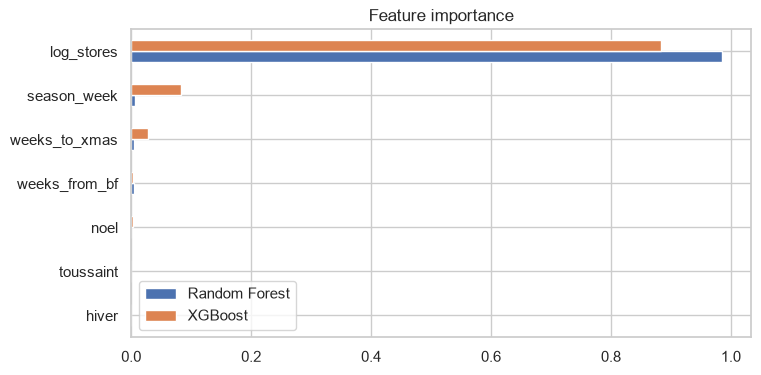

Total réel validation : 36,582
Total prévu Seasonal naive : 44,038
Total prévu SARIMAX        : 43,936
Total prévu Random Forest  : 45,518
Total prévu XGBoost        : 44,854


,MSE,RMSE,MAE,WAPE
SARIMAX,"307,184",554,317,34.7%
Random Forest,"368,001",607,391,42.7%
XGBoost,"371,109",609,381,41.6%
Seasonal naive,"409,124",640,392,42.8%
Seasonal naive × n_stores,"416,524",645,395,43.2%
ARIMA,"1,876,560","1,370",907,99.2%


In [20]:
plot_val(['SARIMAX', 'Random Forest', 'XGBoost'], 'Machine learning – validation')

# Importance des features (modèles entraînés sur le fold)
imp = pd.DataFrame({'Random Forest': rf_forecast.model.feature_importances_,
                    'XGBoost': xgb_forecast.model.feature_importances_}, index=ML_FEATURES)
imp.sort_values('Random Forest').plot.barh(figsize=(8, 4), title='Feature importance')
plt.show()

print('Total réel validation :', f'{y_val.sum():,.0f}')
for n in ['Seasonal naive', 'SARIMAX', 'Random Forest', 'XGBoost']:
    print(f'Total prévu {n:<15}: {val_preds[n].sum():,.0f}')
results_table()

### 4.3 Analyse du machine learning

| Modèle | MSE validation | WAPE |
|---|---|---|
| Seasonal naive (référence) | ≈ 409 000 | 42,8 % |
| **SARIMAX** | **≈ 307 000** | **34,7 %** |
| Random Forest | ≈ 368 000 | 42,7 % |
| XGBoost | ≈ 371 000 | 41,6 % |

- Les deux modèles d'arbres font **mieux que le seasonal naive (−10 %)**, mais **moins bien que le SARIMAX**.
- **Importance des features :** `log_stores` explique presque tout. Sur l'échelle log, l'essentiel de la variance
  oppose la saison active (des milliers d'unités) à la hors-saison (quasi 0), et `n_stores` sépare parfaitement les deux.
  Les features de calendrier pèsent très peu : avec une seule saison d'entraînement, les arbres ne peuvent pas
  apprendre de façon fiable l'effet du Black Friday ou de Noël sur la **hauteur** du pic.
- **Forme de la prévision :** les arbres prédisent des « paliers » (valeurs constantes par morceaux) et
  reproduisent le profil de la saison 2021-22 : pic trop tôt et trop bas, puis surestimation de janvier–février.
- **Problème de niveau commun à tous les modèles :** le total prévu sur la validation (≈ 44 000–45 500) dépasse
  nettement le total réel (≈ 36 600), car la saison 2022-23 a été 17 % plus faible que la seule saison vue à
  l'entraînement. Pour la soumission, les modèles sont réentraînés sur **les deux saisons**, ce qui atténue ce biais.
- **Limite structurelle :** avec 50 lignes d'entraînement dans le fold (102 pour la soumission), le machine learning
  ne peut pas exprimer son avantage habituel (interactions complexes entre de nombreuses features).

In [21]:
for name, fn in [('ml_random_forest', rf_forecast), ('ml_xgboost', xgb_forecast)]:
    make_submission(name, fn)

Soumission écrite : ..\submissions\ml_random_forest.csv (40 lignes, total prévu = 40,914)


Soumission écrite : ..\submissions\ml_xgboost.csv (40 lignes, total prévu = 40,390)


## 5. Deep learning simple

Réseaux de neurones simples, entraînés sur les mêmes features ou sur des fenêtres de la série.

### 5.1 MLP

Perceptron multicouche sur les features de l'étape 4.

In [22]:
# TODO

### 5.2 LSTM

Réseau récurrent sur des séquences de semaines.

In [23]:
# TODO

## 6. Deep learning avancé

Architectures récentes présentées par Decathlon (TFT, N-HiTS).

### 6.1 TFT (Temporal Fusion Transformer)

In [24]:
# TODO

### 6.2 N-HiTS

In [25]:
# TODO

## 7. Comparaison des modèles et soumission finale

In [26]:
results_table()

,MSE,RMSE,MAE,WAPE
SARIMAX,"307,184",554,317,34.7%
Random Forest,"368,001",607,391,42.7%
XGBoost,"371,109",609,381,41.6%
Seasonal naive,"409,124",640,392,42.8%
Seasonal naive × n_stores,"416,524",645,395,43.2%
ARIMA,"1,876,560","1,370",907,99.2%


*À compléter : choix du modèle final (ou ensemble) et justification.*